In [1]:
import pandas as pd
import numpy as np
import regex as re
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from imblearn.over_sampling import SMOTE
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from collections import defaultdict
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r'D:\Download\doc\SK_WIDIASIH\dataset_kompas\databersih\data_karakteristikkejahatan.csv')

In [3]:
df.head()

,judul_berita,isi_berita,text_clean,label_kriminal,label_krim_gabungan,jenis_kriminal,prediksi_jenis_dt,motif_kejahatan,prediksi_motif_dt,hubungan_pelaku_korban,prediksi_hubungan_dt,karakteristik_kejahatan,prediksi_karakteristik_dt
0,Bocah yang Jasadnya Terbungkus Sarung Tewas Di...,"JAKARTA, KOMPAS.com - Pasangan pengemis bernam...",pasangan pengemis bernama sinta dewi 22 aidil ...,True,1,Pembunuhan,Pembunuhan,"Dendam, Emosi & Konflik","Dendam, Emosi & Konflik",Saling Kenal,Saling Kenal,Impulsif/Spontan,Impulsif/Spontan
1,Orangtua Bocah Tewas dalam Sarung Sering Aniay...,"JAKARTA, KOMPAS.com - Sinta Dewi (22) dan Aidi...",sinta dewi 22 aidil zacky rahman 19 pengemis d...,True,1,Penganiayaan & Kekerasan,Penganiayaan & Kekerasan,"Dendam, Emosi & Konflik","Dendam, Emosi & Konflik",Tidak Kenal/Tidak Diketahui,Tidak Kenal/Tidak Diketahui,Premeditasi/Terencana,Premeditasi/Terencana
2,Orangtua Bocah Tewas dalam Sarung Aniaya Anakn...,"JAKARTA, KOMPAS.com - Dua pengemis bernama Sin...",pengemis bernama sinta dewi 22 aidil zacky rah...,True,1,Pembunuhan,Penganiayaan & Kekerasan,"Dendam, Emosi & Konflik","Dendam, Emosi & Konflik",Tidak Kenal/Tidak Diketahui,Tidak Kenal/Tidak Diketahui,Impulsif/Spontan,Impulsif/Spontan
3,Orangtua Bocah Tewas Terbungkus Sarung di Beka...,"JAKARTA, KOMPAS.com - Balita berinisial RMR (3...",balita berinisial rmr 3 ditemukan tewas terbun...,True,1,Penganiayaan & Kekerasan,Penganiayaan & Kekerasan,"Dendam, Emosi & Konflik","Dendam, Emosi & Konflik",Saling Kenal,Saling Kenal,Impulsif/Spontan,Impulsif/Spontan
4,"Motif Orangtua Bunuh Anak di Bekasi, Emosi kar...","JAKARTA, KOMPAS.com - Polisi mengungkapkan, or...",polisi orangtua bernama sinta dewi 22 aidil za...,True,1,Pembunuhan,Pembunuhan,"Dendam, Emosi & Konflik","Dendam, Emosi & Konflik",Tidak Kenal/Tidak Diketahui,Tidak Kenal/Tidak Diketahui,Impulsif/Spontan,Impulsif/Spontan


In [4]:
print("Jumlah baris data:")
jumlah_baris = len(df)
print(f"   Total baris data: {jumlah_baris}")

Jumlah baris data:
   Total baris data: 63856


In [5]:
jumlah_duplikasi = df.duplicated().sum()
print("Cek data duplikasi:")
print(f"   Jumlah baris duplikat: {jumlah_duplikasi}")

Cek data duplikasi:
   Jumlah baris duplikat: 0


In [6]:
print("Cek data kosong (Missing Values):")
data_kosong = df.isnull().sum()
print(data_kosong)

Cek data kosong (Missing Values):
judul_berita                 0
isi_berita                   0
text_clean                   0
label_kriminal               0
label_krim_gabungan          0
jenis_kriminal               0
prediksi_jenis_dt            0
motif_kejahatan              0
prediksi_motif_dt            0
hubungan_pelaku_korban       0
prediksi_hubungan_dt         0
karakteristik_kejahatan      0
prediksi_karakteristik_dt    0
dtype: int64


In [7]:
PATTERN_KEJADIAN = (
    r'dibacok|ditikam|dibunuh|disiram|ditembak|dianiaya|diyaniaya|penganiayaan|'
    r'ditusuk|dipukul|dicekik|pembacokan|penyerangan|digorok|dibakar|menikam|'
    r'menusuk|membunuh|menganiaya|memukul|mencekik|sabetan|menyabet|menyabetkan|'
    r'melukai|tewas|dikeroyok|pengeroyokan|dihajar|dieksekusi|menembak|'
    r'pembunuhan|penembakan|pemukulan|tawuran|ditebas|menebas|dibantai|'
    r'membantai|pembantaian|disiksa|menyiksa|penyiksaan|diracun|meracuni|'
    r'diperkosa|memerkosa|dicabuli|mencabuli|pencabulan|pemerkosaan|pelecehan|'
    r'disekap|menyekap|penyekapan|asusila|video\s+asusila|diculik|memproduksi\s+video\s+asusila|terencana\s+video|menjual\s+video\s+asusila|'
    r'penculikan|menculik|rudapaksa|dirudapaksa|merudapaksa|pelecehan\s+seksual|'
    r'sodomi|disodomi|prostitusi|mucikari|perdagangan\s+orang|'
    r'dirampok|merampok|perampokan|dicuri|mencuri|pencurian|membobol|pembobolan|'
    r'menggasak|digasak|dijambret|menjambret|penjambretan|diperas|memeras|'
    r'pemerasan|mengutil|disatroni|menyaru|penodongan|ditodong|'
    r'curanmor|begal|dibegal|membegal|pencopetan|dicopet|mencopet|maling|'
    r'kemalingan|pungli|pemalakan|dipalak|memalak|menjarah|dijarah|penjarahan|'
    r'menipu|ditipu|penipuan|penggelapan|digelapkan|melarikan\s+diri|kabur|'
    r'membawa\s+kabur|bawa\s+kabur|paspor\s+palsu|palsu|pemalsuan|memalsukan|ilegal|'
    r'korupsi|dikorupsi|mengkorupsi|suap|menyuap|disuap|pencucian\s+uang|tppu|'
    r'hoaks|peretasan|diretas|meretas|hacker|judi\s+online|judol|slot|kepulangan|'
    r'narkoba|narkotika|sabu|ekstasi|ganja|psikotropika|sabu-sabu|kedapatan|penyalahgunaan\s+narkotika|'
    r'bandar|kurir|pengedar|diedarkan|mengedarkan|miras|minuman\s+keras|oplosan|'
    r'penyelundupan|diselundupkan|menyelundupkan|'
    r'ketahuan|kepergok|dipergoki|tertangkap\s+basah|kepergok\s+basah'
)

PATTERN_KRONOLOGI = (
    r'kejadian|peristiwa|kejadiannya|kronologi|kronologis|penemuan|ditemukan|'
    r'kronologi\s+kejadian|awal\s+kejadian|ditemukan\s+tewas|ditemukan\s+meninggal|ditemukan\s+bersimpah\s+darah|'
    r'jasad\s+ditemukan|mayat\s+ditemukan|jenazah\s+ditemukan|'
    r'terjadi|melancarkan|aksinya|beraksi|aksi|menjelang|berlangsung|dieksekusi|'
    r'menjalankan\s+aksi|melakukan\s+aksi|melakukan\s+tindakan|'
    r'digrebek|digerebek|penggerebekan|menggerebek|kepergok|dipergoki|terciduk|komplotan|'
    r'operasi\s+tangkap\s+tangan|tangkap\s+tangan|tertangkap\s+tangan|ott|kpk\s+tangkap\s+tangan|'
    r'digerebek\s+saat|ditangkap\s+saat|diamankan\s+saat|'
    r'orang\s+tak\s+dikenal|otk|peristiwa\s+penyerangan|'
    r'berdasarkan\s+keterangan\s+korban|menurut\s+keterangan\s+korban|'
    r'berdasarkan\s+keterangan\s+saksi|menurut\s+keterangan\s+saksi|menurut\s+saksi|sesuai\s+keterangan|'
    r'keterangan\s+saksi|keterangan\s+polisi|laporan\s+polisi|pengakuan\s+pelaku|hasil\s+interogasi|'
    r'saat\s+(?:sedang\s+)?beraksi|saat\s+melakukan\s+aksi|saat\s+melancarkan\s+aksi|ketika\s+(?:sedang\s+)?beraksi|'
    r'saat\s+sedang\s+menggasak|saat\s+hendak\s+kabur|baru\s+saja\s+(?:mencuri|membobol|menggasak|merampok)|'
    r'saat\s+beraksi|saat\s+melakukan|tengah\s+asyik|sedang\s+asyik|'
    r'saat\s+hendak|saat\s+akan|ketika\s+hendak|ketika\s+sedang|saat\s+berada\s+di|'
    r'saat\s+perjalanan|saat\s+pulang|saat\s+melintas|'
    r'hendak|saat\s+kejadian|pada\s+saat|pada\s+hari|diperkirakan|sekitar\s+pukul|sekitar\s+jam|'
    r'pada\s+pukul|pada\s+jam|sekira|sekitar|kirakira|kira-kira|berkisar|tepat\s+pukul|tepat\s+jam'
)
 
PATTERN_WAKTU_SIDANG_PERS = (
    r'(?:sidang|persidangan)\s+(?:digelar|dimulai|berlangsung|dilaksanakan|dibuka|ditunda|selesai|dipimpin)|'
    r'(?:agenda|ruang|jadwal)\s+sidang|persidangan|pemanggilan\s+saksi|'
    r'pembacaan\s+(?:vonis|dakwaan|tuntutan|eksepsi)|'
    r'kedatangan\s+jenazah|kargo\s+jenazah|tiba\s+di\s+bandara|pemakaman|dimakamkan|prosesi\s+penyambutan\s+keluarga|'
    r'dievakuasi|evakuasi|dibawa\s+ke\s+rs|dilarikan\s+ke\s+rs|autopsi|otopsi|'
    r'konferensi\s+pers|jumpa\s+pers'
)

MAP_KATA_WAKTU = {
    'sepertiga malam terakhir': 'Malam/Dini Hari', 'sepertiga malam': 'Malam/Dini Hari',
    'dini hari tadi': 'Malam/Dini Hari', 'menjelang dini hari': 'Malam/Dini Hari',
    'jam makan malam': 'Malam/Dini Hari', 'makan malam': 'Malam/Dini Hari',
    'kemarin malam': 'Malam/Dini Hari', 'menjelang malam': 'Malam/Dini Hari',
    'tengah malam': 'Malam/Dini Hari', 'larut malam': 'Malam/Dini Hari',
    'tadi malam': 'Malam/Dini Hari', 'malam hari': 'Malam/Dini Hari',
    'malam-malam': 'Malam/Dini Hari', 'sholat isya': 'Malam/Dini Hari',
    'solat isya': 'Malam/Dini Hari', 'shalat isya': 'Malam/Dini Hari',
    'salat isya': 'Malam/Dini Hari', 'habis isya': 'Malam/Dini Hari',
    'usai isya': 'Malam/Dini Hari', 'setelah isya': 'Malam/Dini Hari',
    'pasca isya': 'Malam/Dini Hari', "ba'da isya": 'Malam/Dini Hari',
    'bada isya': 'Malam/Dini Hari', 'sholat tahajud': 'Malam/Dini Hari',
    'dini hari': 'Malam/Dini Hari', 'dinihari': 'Malam/Dini Hari',
    'malam': 'Malam/Dini Hari', 'semalam': 'Malam/Dini Hari',
    'isya': 'Malam/Dini Hari', 'isha': 'Malam/Dini Hari', 'tahajud': 'Malam/Dini Hari',

    'jam makan siang': 'Siang/Sore', 'waktu makan siang': 'Siang/Sore',
    'istirahat siang': 'Siang/Sore', 'makan siang': 'Siang/Sore',
    'tengah hari': 'Siang/Sore', 'menjelang siang': 'Siang/Sore',
    'terik matahari': 'Siang/Sore', 'tadi siang': 'Siang/Sore',
    'siang hari': 'Siang/Sore', 'sholat dzuhur': 'Siang/Sore',
    'solat dzuhur': 'Siang/Sore', 'shalat dzuhur': 'Siang/Sore',
    'salat dzuhur': 'Siang/Sore', 'sholat zuhur': 'Siang/Sore',
    'solat zuhur': 'Siang/Sore', 'habis dzuhur': 'Siang/Sore',
    'usai dzuhur': 'Siang/Sore', 'setelah dzuhur': 'Siang/Sore',
    'pasca dzuhur': 'Siang/Sore', "ba'da dzuhur": 'Siang/Sore',
    'bada dzuhur': 'Siang/Sore', 'habis zuhur': 'Siang/Sore',
    'usai zuhur': 'Siang/Sore', 'setelah zuhur': 'Siang/Sore',
    'pasca zuhur': 'Siang/Sore', "ba'da zuhur": 'Siang/Sore',
    'bada zuhur': 'Siang/Sore', 'sore hari': 'Siang/Sore',
    'sore-sore': 'Siang/Sore', 'sore sore': 'Siang/Sore',
    'tadi sore': 'Siang/Sore', 'menjelang sore': 'Siang/Sore',
    'sholat ashar': 'Siang/Sore', 'solat ashar': 'Siang/Sore',
    'shalat ashar': 'Siang/Sore', 'salat ashar': 'Siang/Sore',
    'sholat asar': 'Siang/Sore', 'solat asar': 'Siang/Sore',
    'habis ashar': 'Siang/Sore', 'usai ashar': 'Siang/Sore',
    'setelah ashar': 'Siang/Sore', 'pasca ashar': 'Siang/Sore',
    "ba'da ashar": 'Siang/Sore', 'bada ashar': 'Siang/Sore',
    'habis asar': 'Siang/Sore', 'usai asar': 'Siang/Sore',
    'setelah asar': 'Siang/Sore', 'pasca asar': 'Siang/Sore',
    'sholat maghrib': 'Siang/Sore', 'solat maghrib': 'Siang/Sore',
    'shalat maghrib': 'Siang/Sore', 'salat maghrib': 'Siang/Sore',
    'sholat magrib': 'Siang/Sore', 'solat magrib': 'Siang/Sore',
    'habis maghrib': 'Siang/Sore', 'usai maghrib': 'Siang/Sore',
    'setelah maghrib': 'Siang/Sore', 'pasca maghrib': 'Siang/Sore',
    "ba'da maghrib": 'Siang/Sore', 'bada maghrib': 'Siang/Sore',
    'habis magrib': 'Siang/Sore', 'usai magrib': 'Siang/Sore',
    'setelah magrib': 'Siang/Sore', 'pasca magrib': 'Siang/Sore',
    'menjelang maghrib': 'Siang/Sore', 'menjelang magrib': 'Siang/Sore',
    'matahari terbenam': 'Siang/Sore', 'terbenam matahari': 'Siang/Sore',
    'siang': 'Siang/Sore', 'sore': 'Siang/Sore', 'dzuhur': 'Siang/Sore',
    'zuhur': 'Siang/Sore', 'duhur': 'Siang/Sore', 'ashar': 'Siang/Sore',
    'asar': 'Siang/Sore', 'maghrib': 'Siang/Sore', 'magrib': 'Siang/Sore',
    'senja': 'Siang/Sore', 'petang': 'Siang/Sore',

    'pagi hari': 'Pagi Hari', 'pagi pagi': 'Pagi Hari',
    'pagi-pagi': 'Pagi Hari', 'tadi pagi': 'Pagi Hari',
    'menjelang pagi': 'Pagi Hari', 'pagi buta': 'Pagi Hari',
    'sholat subuh': 'Pagi Hari', 'solat subuh': 'Pagi Hari',
    'shalat subuh': 'Pagi Hari', 'salat subuh': 'Pagi Hari',
    'waktu subuh': 'Pagi Hari', 'usai subuh': 'Pagi Hari',
    'setelah subuh': 'Pagi Hari', 'pasca subuh': 'Pagi Hari',
    'habis subuh': 'Pagi Hari', 'waktu imsak': 'Pagi Hari',
    'waktu imsyak': 'Pagi Hari', 'waktu sarapan': 'Pagi Hari',
    'terbit matahari': 'Pagi Hari', 'matahari terbit': 'Pagi Hari',
    'pagi': 'Pagi Hari', 'fajar': 'Pagi Hari', 'subuh': 'Pagi Hari',
    'imsak': 'Pagi Hari', 'imsyak': 'Pagi Hari', 'sarapan': 'Pagi Hari'
}

KATA_WAKTU_SORTED = sorted(MAP_KATA_WAKTU.keys(), key=len, reverse=True)

def klasifikasi_jam(h, m=0):
    t = h * 60 + m
    if t < 180:   return 'Malam/Dini Hari'  # 00.00 - 02.59
    if t < 600:   return 'Pagi Hari'        # 03.00 - 09.59
    if t < 1140:  return 'Siang/Sore'       # 10.00 - 18.59
    return 'Malam/Dini Hari'                # 19.00 - 23.59

def normalisasi_dan_ekstrak_jam(teks_lower):
    teks_temp = teks_lower

    pola_jam_3 = r'\b(?:pukul|jam)\s*(0?3)[\s.:]*(?:00)?\s*(?:dini\s*hari|dinihari|wib|wita|wit)?\b'
    teks_temp = re.sub(pola_jam_3, r'JAM_03_00', teks_temp)

    def konversi_12jam(match):
        h = int(match.group(1))
        ket = match.group(2).strip()
        if ket in ['siang', 'sore'] and h < 12:
            h += 12
        elif ket in ['malam'] and h < 12 and h >= 7:
            h += 12
        elif ket in ['malam'] and h == 12:
            h = 0
        return f"JAM_{h:02d}_00"

    pola_12jam = r'\b(?:pukul|jam)\s*([0-1]?[0-9])\s*(siang|sore|malam|pagi)\b'
    teks_temp = re.sub(pola_12jam, konversi_12jam, teks_temp)

    teks_temp = re.sub(r'\b(?:pukul|jam)\s*([0-2]?[0-9])[\s.:]+([0-5][0-9])\b', r'JAM_\1_\2', teks_temp)
    teks_temp = re.sub(r'\b([0-2]?[0-9])[:.]([0-5][0-9])\b', r'JAM_\1_\2', teks_temp)

    teks_temp = re.sub(r'\b(?:pukul|jam)\s*([0-2]?[0-9])\s*(?:wib|wita|wit)?\b', r'JAM_\1_00', teks_temp)

    return teks_temp

def hitung_skor_kandidat(teks_lower, start_pos, end_pos, ada_kejadian_global):
    base_score = 1.0 if ada_kejadian_global else 0.0

    z1_start = max(0, start_pos - 50)
    z1_end = min(len(teks_lower), end_pos + 50)
    zona_1 = teks_lower[z1_start:z1_end]

    is_waktu_sidang_z1 = len(re.findall(PATTERN_WAKTU_SIDANG_PERS, zona_1))
    if is_waktu_sidang_z1 > 0:
        return -10.0

    z2_start = max(0, start_pos - 150)
    z2_end = min(len(teks_lower), end_pos + 150)
    zona_2 = teks_lower[z2_start:z2_end]

    is_waktu_sidang_z2 = len(re.findall(PATTERN_WAKTU_SIDANG_PERS, zona_2)) - is_waktu_sidang_z1
    kejadian_z1 = len(re.findall(PATTERN_KEJADIAN, zona_1))
    kejadian_z2 = len(re.findall(PATTERN_KEJADIAN, zona_2)) - kejadian_z1

    kronologi_z1 = len(re.findall(PATTERN_KRONOLOGI, zona_1))
    kronologi_z2 = len(re.findall(PATTERN_KRONOLOGI, zona_2)) - kronologi_z1

    skor_kejadian = (kejadian_z1 * 4.0) + (kejadian_z2 * 2.0)
    skor_kronologi = (kronologi_z1 * 2.0) + (kronologi_z2 * 1.0)
    penalti_sidang_umum = (is_waktu_sidang_z2 * 2.0)

    return base_score + skor_kejadian + skor_kronologi - penalti_sidang_umum

def label_waktu (teks_berita):
    if not isinstance(teks_berita, str) or not teks_berita.strip():
        return 'Tidak Teridentifikasi'

    teks_lower = teks_berita.lower()
    ada_kejadian_global = bool(re.search(PATTERN_KEJADIAN, teks_lower))

    teks_temp = normalisasi_dan_ekstrak_jam(teks_lower)

    kandidat_waktu = []

    for m in re.finditer(r'JAM_([0-2]?[0-9])_([0-5][0-9])', teks_temp):
        h, min_ = int(m.group(1)), int(m.group(2))
        if 0 <= h <= 23:
            kandidat_waktu.append((m.start(), m.end(), klasifikasi_jam(h, min_)))

    for kata in KATA_WAKTU_SORTED:
        for m in re.finditer(rf'\b{re.escape(kata)}\b', teks_temp):
            kandidat_waktu.append((m.start(), m.end(), MAP_KATA_WAKTU[kata]))

    if not kandidat_waktu:
        return 'Tidak Teridentifikasi'

    skor_kandidat_list = []
    for start, end, label in kandidat_waktu:
        skor = hitung_skor_kandidat(teks_temp, start, end, ada_kejadian_global)
        skor_kandidat_list.append((label, skor))

    skor_kandidat_list.sort(key=lambda x: x[1], reverse=True)
    top_label, top_skor = skor_kandidat_list[0]

    return top_label if top_skor > 0.5 else 'Tidak Teridentifikasi'

tqdm.pandas()
df['waktu'] = df['text_clean'].progress_apply(label_waktu)

100%|██████████| 63856/63856 [04:52<00:00, 218.63it/s]


In [17]:
dist_kriminal = pd.DataFrame({
    'Jumlah': df['waktu'].value_counts(dropna=False),
    'Persentase (%)': (df['waktu'].value_counts(dropna=False, normalize=True) * 100).round(2)
})

print("DISTRIBUSI WAKTU")
print(dist_kriminal)

DISTRIBUSI WAKTU
                       Jumlah  Persentase (%)
waktu                                        
Tidak Teridentifikasi   33212           52.01
Malam/Dini Hari         14700           23.02
Siang/Sore               9767           15.30
Pagi Hari                6177            9.67


## Cek

In [ ]:
pd.set_option('display.max_colwidth', None)
df_sampel = df[df['waktu'] == 'Malam/Dini Hari'].sample(n=10)

for index, row in df_sampel.iterrows():
    print(f"LABEL Jenis: {row['waktu']} | INDEX: {index}")
    print(f"BERITA ISI : {row['text_clean']}")
    print("-" * 80)
    print("\n")

In [ ]:
target_indices = [45180,22701,2194,512,8344,43854,56717,53987,21135,40160]

for idx in target_indices:
    if idx in df.index:
        print(f"INDEX           : {idx}")
        print(f"waktu  : {df.loc[idx, 'waktu']}") 
        print(f"BERITA ISI      : \n{df.loc[idx, 'text_clean']}")
        print("\n" + "="*80 + "\n")
    else:
        print(f"Index {idx} tidak ditemukan dalam DataFrame.")

## ML

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    df["text_clean"],
    df["waktu"],
    test_size=0.2,
    random_state=42,
    stratify=df["waktu"],
)

In [13]:
URUTAN_KELAS = sorted(y_train.unique())

tfidf = TfidfVectorizer(ngram_range=(1, 3), max_features=25000)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [14]:
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_tfidf, y_train
)

C:\Users\Java Computer\anaconda3\envs\tensorflow\lib\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


In [15]:
model_gini = DecisionTreeClassifier(criterion='gini', random_state=42)
model_gini.fit(X_train_balanced, y_train_balanced)  
pred_test_gini = model_gini.predict(X_test_tfidf)

model_entropy = DecisionTreeClassifier(criterion='entropy', random_state=42)
model_entropy.fit(X_train_balanced, y_train_balanced)  
pred_test_entropy = model_entropy.predict(X_test_tfidf)

pred_combined_multiclass = np.where(
    pred_test_gini == pred_test_entropy, 
    pred_test_gini, 
    'Tidak_Sama'
)

 EVALUASI: MODEL GINI (SMOTE)

[1] CLASSIFICATION REPORT:
                       precision    recall  f1-score   support

      Malam/Dini Hari       0.88      0.86      0.87      2940
            Pagi Hari       0.76      0.79      0.77      1235
           Siang/Sore       0.82      0.82      0.82      1954
Tidak Teridentifikasi       0.97      0.97      0.97      6643

             accuracy                           0.91     12772
            macro avg       0.86      0.86      0.86     12772
         weighted avg       0.91      0.91      0.91     12772


[2] CONFUSION MATRIX:


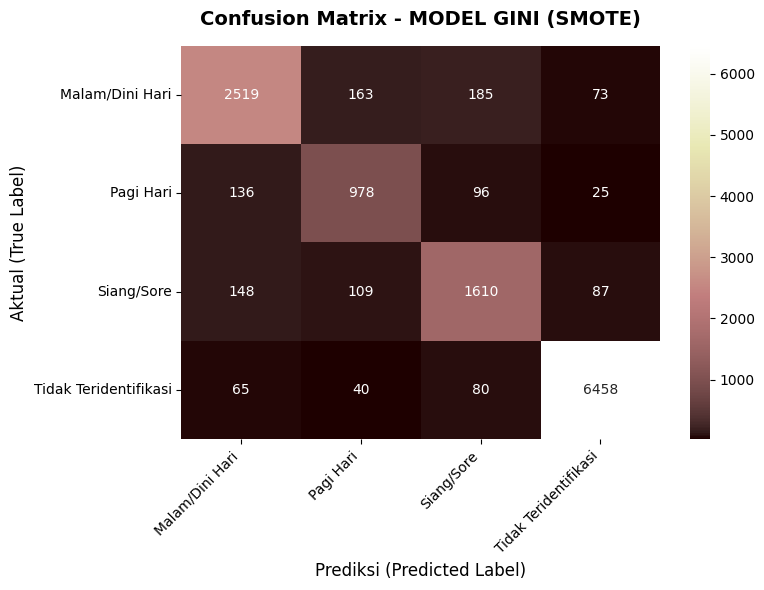


xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

 EVALUASI: MODEL ENTROPY (SMOTE)

[1] CLASSIFICATION REPORT:
                       precision    recall  f1-score   support

      Malam/Dini Hari       0.87      0.86      0.87      2940
            Pagi Hari       0.75      0.80      0.78      1235
           Siang/Sore       0.82      0.83      0.82      1954
Tidak Teridentifikasi       0.98      0.97      0.98      6643

             accuracy                           0.91     12772
            macro avg       0.86      0.86      0.86     12772
         weighted avg       0.91      0.91      0.91     12772


[2] CONFUSION MATRIX:


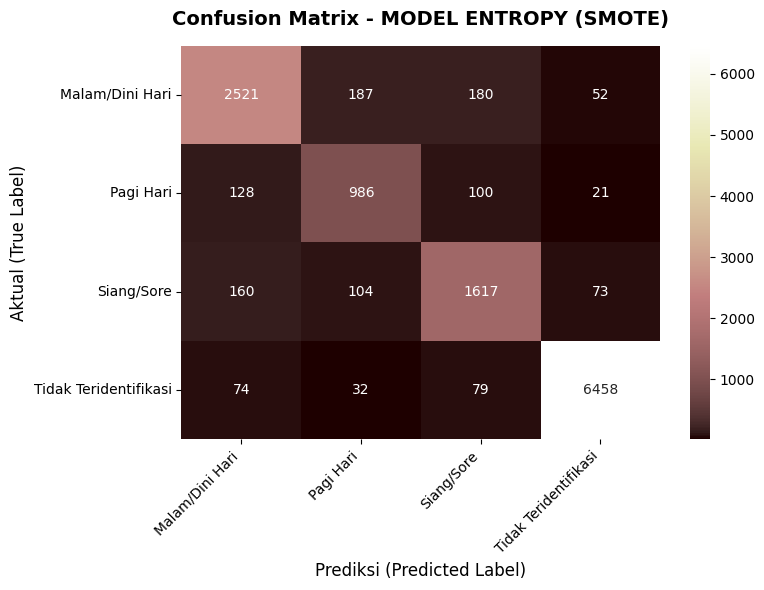


xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

 EVALUASI: MODEL GABUNGAN (LOGIKA AND)

[1] CLASSIFICATION REPORT:
                       precision    recall  f1-score   support

      Malam/Dini Hari       0.92      0.79      0.85      2940
            Pagi Hari       0.84      0.71      0.77      1235
           Siang/Sore       0.89      0.76      0.82      1954
Tidak Teridentifikasi       0.99      0.96      0.98      6643
           Tidak_Sama       0.00      0.00      0.00         0

             accuracy                           0.87     12772
            macro avg       0.73      0.64      0.68     12772
         weighted avg       0.94      0.87      0.90     12772


[2] CONFUSION MATRIX:


C:\Users\Java Computer\anaconda3\envs\tensorflow\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Java Computer\anaconda3\envs\tensorflow\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Java Computer\anaconda3\envs\tensorflow\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(r

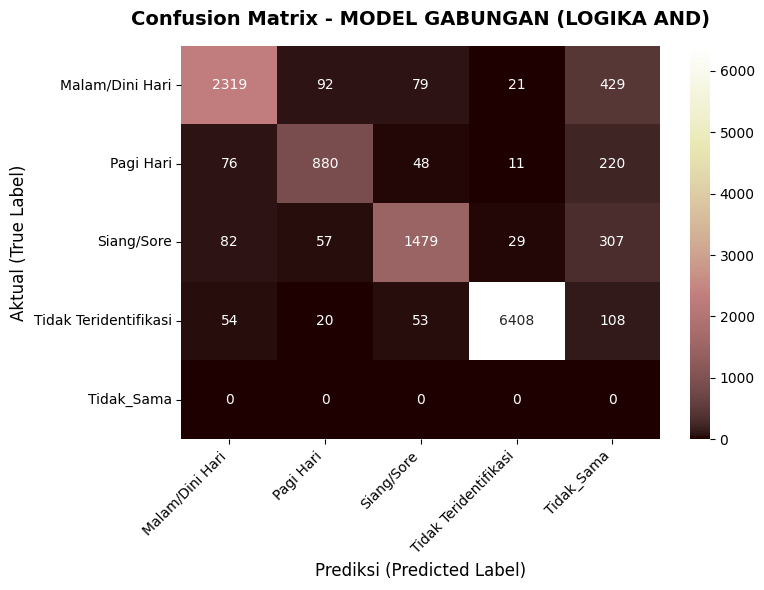


xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx



In [19]:
eval_dict = {
    'MODEL GINI (SMOTE)': pred_test_gini,
    'MODEL ENTROPY (SMOTE)': pred_test_entropy,
    'MODEL GABUNGAN (LOGIKA AND)': pred_combined_multiclass,}

for model_name, pred in eval_dict.items():
    print("=" * 70)
    print(f" EVALUASI: {model_name}")
    print("=" * 70)

    print("\n[1] CLASSIFICATION REPORT:")
    print(classification_report(y_test, pred))

    print("\n[2] CONFUSION MATRIX:")
    labels = sorted(list(set(y_test) | set(pred)))
    cm = confusion_matrix(y_test, pred, labels=labels)

    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm,
        annot=True,  
        fmt='d',  
        cmap='pink',  
        xticklabels=labels,  
        yticklabels=labels,  
        cbar=True,  
    )

    plt.title(
        f'Confusion Matrix - {model_name}',
        fontsize=14,
        fontweight='bold',
        pad=15,
    )
    plt.xlabel('Prediksi (Predicted Label)', fontsize=12)
    plt.ylabel('Aktual (True Label)', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()  
    print("\n" + "x" * 70 + "\n")

In [20]:
df_hasil_waktu = df.copy()
X_clean_tfidf = tfidf.transform(df_hasil_waktu['text_clean'])
pred_gini = model_gini.predict(X_clean_tfidf)
pred_entropy = model_entropy.predict(X_clean_tfidf)

df_hasil_waktu['prediksi_waktu_dt'] = np.where(
    pred_gini == pred_entropy, 
    pred_gini, 
    'Tidak_Sama'
)
df_hasil_waktu = df_hasil_waktu[df_hasil_waktu['prediksi_waktu_dt'] != 'Tidak_Sama']

nama_file_final = "data_waktuSMOTE.csv"
df_hasil_waktu.to_csv(nama_file_final, index=False)

print(f" Selesai! Data berhasil difilter.")
print(f" Sisa data bersih tersimpan: {len(df_hasil_waktu)} baris di file '{nama_file_final}'")

 Selesai! Data berhasil difilter.
 Sisa data bersih tersimpan: 62792 baris di file 'data_waktuSMOTE.csv'
